# ID6004W Industrial Vision - Assignment 3
### Lectures 07-13: SIFT, Projective Geometry, Cameras, and Homographies

| | |
|---|---|
| **Released** | Oct 24th 2026 |
| **Due** | Nov 11th 2026 (5.00 PM IST) |
| **Total** | 100 marks (Theory 60 + Programming 40; will be scaled down appropriately later) |

## Instructions

**Working in Colab.** Open this notebook in Google Colab and immediately use *File → Save a copy in Drive*; work only in your copy. Type your answers in the cells marked **Your answer**, directly below each question (double-click a cell to edit it). Mathematics can be typed in LaTeX between `$...$` or `$$...$$`. Photographs of hand-written working are **not** accepted in place of typed answers.

- **The writing must be your own**, for both the theory answers and the code.
- Wherever a numerical answer is asked for, show the intermediate steps.
- Cells marked **Optional check** are not graded. Use them to verify a hand calculation numerically, but the answer you submit must be derived by hand with the steps shown.
- Part B is done in this notebook, and the notebook is also your report: the cells make the figures, and your written answers go in the **Your answer** cells of Part B. Run every cell from top to bottom (*Runtime → Restart and run all*) before you submit, so that all outputs and figures are visible in the file.
- **Submission.** Make a **single `.zip`** named `<ROLLNO>_assignment3.zip` that contains (1) this notebook with all outputs, downloaded with *File → Download → Download .ipynb* and named `<ROLLNO>_assignment3.ipynb`, and (2) the photographs you took for Part B. Upload it here: [SUBMISSION LINK](https://forms.gle/kem7ogoLSk89omW39). For queries contact Rishabh Shukla (da26e011@smail.iitm.ac.in). The form link will be disabled after the deadline. Follow the naming convention strictly.
- **Late policy:** 10 marks will be deducted for each day the assignment is submitted late after the due date.

## Student details

- **Name:** Sohang Chopra
- **Roll number:** DA25M622

In [1]:
# Before run this cell, upload 'assignment3_data' directory on colab after this run all cell.
# Setup: run this cell once. It downloads the data for this assignment into the Colab session.
# Colab deletes session files when the runtime restarts; just run the cell again.
BASE_URL = "REPLACE_WITH_BASE_URL"   # set by the instructor, do not change
DATA = "assignment3_data"

import os
if not os.path.isdir(DATA):
    !wget -q -O {DATA}.zip "{BASE_URL}/{DATA}.zip"
    !unzip -q -o {DATA}.zip && rm -f {DATA}.zip
print(DATA, "->", sorted(os.listdir(DATA)))



assignment3_data -> ['aloeL.jpg', 'aloeR.jpg', 'boat1.jpg', 'boat2.jpg', 'boat3.jpg', 'boat4.jpg', 'boat5.jpg', 'newspaper1.jpg', 'newspaper2.jpg', 'sample_output']


In [2]:
import os
import sys
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV", cv2.__version__)       # SIFT needs OpenCV >= 4.4; Colab's default is fine

OpenCV 5.0.0


---
# Part A - Theory  [60 marks]

---
## Question 1. SIFT: blur levels, refinement and the descriptor  [14 marks]

**(a) Blur levels in one octave.** **[4]**

Lowe's SIFT uses $s=3$ scales per octave, and each octave starts at $\sigma_0=1.6$.

1. Find $k$ and the six blur levels $\sigma_0,\dots,\sigma_5$ of the first octave (three decimals). Which three DoG levels are searched for extrema, and why not the other two?
2. The level $\sigma_3=3.2$ is made by blurring the level $\sigma_2$ once more, not the original image. What standard deviation must this extra blur have?
3. A student uses an extra blur of $\sigma_3-\sigma_2$ instead. What $\sigma$ does their level really have? In one sentence, what rule did they get wrong?

**Your answer 1(a).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(b) Refining a keypoint, and the two rejection tests.** **[5]**

A DoG extremum found on the sample grid has value $D=0.045$, and gradient and Hessian

$$
\nabla D=\begin{bmatrix}0.012\\-0.006\\0.020\end{bmatrix},\qquad
\mathbf H_D=\begin{bmatrix}-0.10&0.02&0.00\\0.02&-0.08&0.01\\0.00&0.01&-0.05\end{bmatrix},
$$

with the coordinates in the order $(x,y,\sigma)$.

1. Compute the sub-pixel offset $\hat{\mathbf{x}}=-\mathbf H_D^{-1}\nabla D$ (three decimals). Do we need to move to a neighbouring sample and fit again?
2. Compute the DoG value at the refined position and apply the contrast test with threshold $0.03$.
3. Apply the edge test with $r_{\max}=10$ to this keypoint (use the $2\times2$ spatial part of $\mathbf H_D$). Then apply it to a second keypoint whose $2\times2$ spatial Hessian is $\begin{bmatrix}-0.30&0.05\\0.05&-0.02\end{bmatrix}$. For the keypoint that is rejected, find the ratio $r$ of its two principal curvatures.

**Your answer 1(b).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

In [5]:
# Optional check for 1(b).
D0 = 0.045
gD = np.array([0.012, -0.006, 0.020])
HD = np.array([[-0.10, 0.02, 0.00],
               [0.02, -0.08, 0.01],
               [0.00, 0.01, -0.05]])
H2 = np.array([[-0.30, 0.05],
               [0.05, -0.02]])

# TODO (optional): the offset, the refined DoG value, and tr^2/det for both spatial Hessians.

**(c) Invariance and matching.** **[5]**

1. A second photograph of the same scene has $I'=1.5\,I+20$. Which step of the descriptor computation removes the $+20$? Which step removes the factor $1.5$?
2. Now the second photograph is the first one rotated by $30^{\circ}$. The reference orientation $\theta$ of the keypoint is used in two places when the descriptor is built. Name both. What goes wrong if we only correct the gradient angles, and keep the sampling grid lined up with the image axes?
3. Two keypoints in image 1 are matched against image 2. Keypoint 1 has nearest and second-nearest descriptor distances $d_1=180$, $d_2=210$. Keypoint 2 has $d_1=250$, $d_2=480$. Apply Lowe's ratio test at $0.8$ to each. Then explain why a fixed rule "accept if $d_1<200$" gives the wrong decision for both.

**Your answer 1(c).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

---
## Question 2. SIFT: keypoints, orientation and octaves  [6 marks]

**(a) Is this a keypoint?** **[2]**

SIFT looks for keypoints in the DoG images. Below are the DoG values around one sample: its own level (middle), the level just below (left) and the level just above (right). The sample itself is the centre of the middle grid.

$$
\underbrace{\begin{bmatrix}0.01&0.02&0.00\\0.03&-0.02&0.01\\0.02&0.00&0.01\end{bmatrix}}_{\text{level below}}\qquad
\underbrace{\begin{bmatrix}0.02&0.01&0.03\\0.00&\mathbf{-0.06}&0.02\\0.01&0.02&0.00\end{bmatrix}}_{\text{same level}}\qquad
\underbrace{\begin{bmatrix}0.03&0.02&0.01\\0.02&-0.04&0.03\\0.01&0.03&0.02\end{bmatrix}}_{\text{level above}}
$$

1. How many values is the centre compared with, and where do they come from?
2. Is the centre kept as a keypoint? If it is, is it a maximum or a minimum, and does it mark a bright blob or a dark blob?
3. Suppose the value directly above the centre were $-0.07$ instead of $-0.04$. Would the centre still be kept? Why is it not enough to compare it only with its 8 neighbours in the same level?

**Your answer 2(a).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(b) The dominant orientation.** **[2]**

To give a keypoint an orientation, SIFT makes a histogram of the gradient angles around it, with 36 bins of $10^{\circ}$ (one bin for $0^{\circ}$-$10^{\circ}$, the next for $10^{\circ}$-$20^{\circ}$, and so on). Each pixel adds its **gradient magnitude** $m$ to the bin of its angle $\varphi$. The pixels around one keypoint have these gradients:

| pixel | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| magnitude $m$ | 5 | 3 | 2 | 4 | 4.5 | 1 | 1 | 1 | 1 |
| angle $\varphi$ | $42^{\circ}$ | $45^{\circ}$ | $47^{\circ}$ | $123^{\circ}$ | $127^{\circ}$ | $300^{\circ}$ | $302^{\circ}$ | $305^{\circ}$ | $308^{\circ}$ |

1. Fill in the histogram (only the bins that are not empty). Which bin gives the dominant orientation?
2. Every other peak that reaches at least $80\%$ of the highest one gives an extra keypoint. How many keypoints are made at this location, and how do they differ from each other?
3. A student adds $1$ for every pixel instead of its magnitude. Which bin wins now? Why is adding the magnitude better?

**Your answer 2(b).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(c) The descriptor, and octaves.** **[2]**

1. The SIFT descriptor uses a $16\times16$ window split into $4\times4$ blocks, and each block gives an 8-bin histogram. How many numbers are in the descriptor, and how many pixels are in each block? If the window were split into $2\times2$ blocks instead (still 8 bins each), how long would the descriptor be?
2. An image is $640\times480$. Ignore Lowe's doubling of the input image, so octave 1 is the image itself, and each new octave keeps every second pixel of every second row. Find the image size in octaves 2 and 3. A keypoint is found at $(100,60)$ in octave 3. Where is it in the original image? Its $16\times16$ descriptor window is measured in octave-3 pixels. How big is this window in the original image?

**Your answer 2(c).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

In [7]:
# Optional check for 2(a) - 2(c).
below = np.array([[0.01, 0.02, 0.00], [0.03, -0.02, 0.01], [0.02, 0.00, 0.01]])
same  = np.array([[0.02, 0.01, 0.03], [0.00, -0.06, 0.02], [0.01, 0.02, 0.00]])
above = np.array([[0.03, 0.02, 0.01], [0.02, -0.04, 0.03], [0.01, 0.03, 0.02]])
m   = np.array([5, 3, 2, 4, 4.5, 1, 1, 1, 1])                     # gradient magnitudes
phi = np.array([42, 45, 47, 123, 127, 300, 302, 305, 308])        # gradient angles in degrees

# TODO (optional): compare same[1, 1] with the other 26 values; build the histogram with
# np.bincount(phi // 10, weights=m, minlength=36) and apply the 80 % rule.

---
## Question 3. The projective plane  [12 marks]

**(a) Points, lines and the line at infinity.** **[4]**

1. Find the homogeneous line $\mathbf{l}$ through the points $(2,1)$ and $(4,5)$. Write it as $y=\dots$ and check that both points lie on it.
2. Find the point where $\mathbf{l}$ meets the line $\mathbf{m}:\;2x-y+1=0$. What does the result tell you about the two lines?
3. Check that this point lies on $\mathbf{l}_\infty$ and on both lines. What do its first two coordinates represent?

**Your answer 3(a).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(b) How $H$ acts on a line and a conic.** **[3]**

Let $H=\mathrm{diag}(2,1,1)$.

1. Find the image under $H$ of the unit circle $C=\mathrm{diag}(1,1,-1)$ and of the line $x=1$. Write both as equations in $(x,y)$.
2. The line $x=1$ touches the circle at $(1,0)$. Using the tangent rule $\mathbf{l}=C\mathbf{x}$, check that the new line touches the new conic at the new point.

**Your answer 3(b).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(c) Counting.** **[2]**

A rectangular poster is photographed, and in the photo it looks like a general quadrilateral.

1. What is the smallest number of point correspondences needed to find the map from the poster to the image? Why?
2. Suppose instead that the camera faces the poster straight on (fronto-parallel), and only zooms, moves and rotates in the poster's plane. How many correspondences are needed now?
3. Of the four properties parallelism, angle, ratio of areas and cross ratio, which ones survive in the general photograph?

**Your answer 3(c).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(d) The cross ratio.** **[3]**

Four points on a line have coordinates $0,1,2,4$.

1. Compute their cross ratio as defined in the lecture, $\mathrm{Cross}(\bar{\mathbf{x}}_1,\bar{\mathbf{x}}_2,\bar{\mathbf{x}}_3,\bar{\mathbf{x}}_4)$.
2. Apply the projectivity $H_{2\times2}=\begin{bmatrix}1&1\\1&2\end{bmatrix}$ to each point, give the four new coordinates, and compute the cross ratio again.
3. Prove that the cross ratio does not change under any projectivity of the line, and that it does not depend on the scale chosen for each homogeneous point.

**Your answer 3(d).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

---
## Question 4. Affine rectification  [10 marks]

A floor of square tiles is photographed. In the photograph, two tile edges of one family appear as the lines $\mathbf{l}_1:\;y=2$ and $\mathbf{l}_2:\;y=x-2$, and two edges of the other family appear as $\mathbf{l}_3:\;x=1$ and $\mathbf{l}_4:\;y=3x$. On the real floor, $\mathbf{l}_1$ and $\mathbf{l}_2$ are parallel, $\mathbf{l}_3$ and $\mathbf{l}_4$ are parallel, and the two families are perpendicular.

**(a) Affine rectification from two vanishing points.** **[5]**

1. Compute the two vanishing points $\mathbf v_1$ (where $\mathbf{l}_1$ and $\mathbf{l}_2$ meet) and $\mathbf v_2$ (where $\mathbf{l}_3$ and $\mathbf{l}_4$ meet), and the imaged line at infinity $\mathbf{l}$ through them.
2. Write down the rectifying matrix $H_P$ from the lecture. Check that it sends $\mathbf{l}$ to $\mathbf{l}_\infty=(0,0,1)^{\top}$, and that it sends each vanishing point to a point at infinity.
3. Compute the images of $\mathbf{l}_1$ and $\mathbf{l}_2$ under $H_P$ and check that they are now parallel.

**Your answer 4(a).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(b) What affine rectification fixes, and what it does not.** **[5]**

Three marks $A=(1,2)$, $B=(2,2)$ and $C=(2.5,2)$ lie on the edge $\mathbf{l}_1$ in the photograph. On the real floor, $B$ is exactly halfway between $A$ and $C$.

1. In the photograph, find the lengths $|AB|$ and $|BC|$. Is $B$ the midpoint of $AC$ in the photograph?
2. Map the three points with $H_P$ to get $A'$, $B'$ and $C'$, and find $|A'B'|$ and $|B'C'|$. Is $B'$ the midpoint of $A'C'$? Which property has affine rectification given back?
3. The points $H_P\mathbf v_1$ and $H_P\mathbf v_2$ are at infinity, and their first two coordinates give the directions of the two families of tile edges in the rectified image. Find the angle between these two directions. On the real floor this angle is $90^{\circ}$. What does your answer tell you about the shape of the tiles in the rectified image?

**Your answer 4(b).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

In [8]:
# Optional check for 4(a) and 4(b).
# l1: y = 2,  l2: y = x - 2,  l3: x = 1,  l4: y = 3x;  marks A = (1, 2), B = (2, 2), C = (2.5, 2).

# TODO (optional): write l1..l4 as homogeneous 3-vectors, get v1, v2 and the vanishing line l with
# np.cross, and build H_P. Points map by HP (then divide by the last entry), lines by np.linalg.inv(HP).T.
HP = None

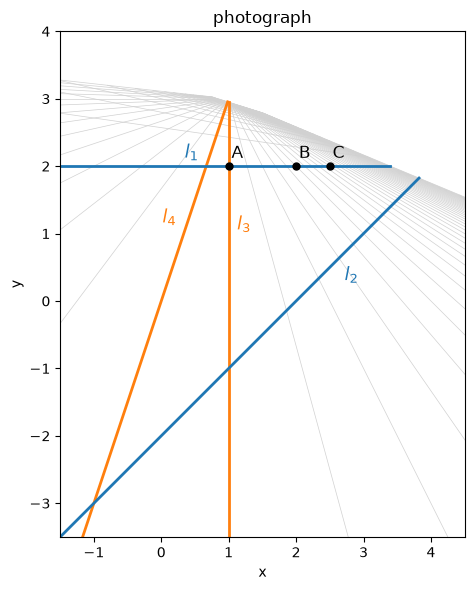

In [9]:
# Run to see Question 4 as a picture. Left: a floor of square tiles as the photograph shows it, with
# l1, l2 (blue), l3, l4 (orange) and the marks A, B, C. Right: the same floor after your H_P.
# Fill in HP in the cell above first; until then only the left panel is drawn.
G = np.array([[0.4, 0.75, 1.0],      # maps floor coordinates (X, Y, 1) to the photograph;
              [0.2, 2.25, 2.0],      # the tiles are 1 x 1 squares on the floor
              [0.1, 0.75, 1.0]])


def draw_floor(HP=None, X=range(-15, 41), Y=range(-6, 26)):
    # Tile edges X = const and Y = const, each cut to the part of the floor in front of the camera,
    # where the third coordinate G[2] @ (X, Y, 1) is positive.
    segs = []
    for x in X:
        y0 = max(Y[0], (0.02 - G[2, 2] - G[2, 0] * x) / G[2, 1])
        if y0 < Y[-1]:
            segs.append((("X", x), (x, y0), (x, Y[-1])))
    for y in Y:
        x0 = max(X[0], (0.02 - G[2, 2] - G[2, 1] * y) / G[2, 0])
        if x0 < X[-1]:
            segs.append((("Y", y), (x0, y), (X[-1], y)))
    # floor line -> (name, colour, floor point where the name is written, text offset)
    named = {("X", 0): ("$l_3$", "tab:orange", (0, -0.6), (6, -6)), ("X", -1): ("$l_4$", "tab:orange", (-1, -0.5), (-20, -6)),
             ("Y", 0): ("$l_1$", "tab:blue", (-1.5, 0), (-6, 6)), ("Y", -1): ("$l_2$", "tab:blue", (3, -1), (4, -16))}
    panels = [("photograph", G)] + ([("after $H_P$", HP @ G)] if HP is not None else [])
    fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 6), squeeze=False)
    for ax, (title, M) in zip(axes[0], panels):
        def img(x, y):
            p = M @ np.array([x, y, 1.0])
            return p[:2] / p[2]

        for k, a, b in segs:
            name, colour = named.get(k, (None, "0.82"))[:2]
            a, b = img(*a), img(*b)
            ax.plot([a[0], b[0]], [a[1], b[1]], color=colour, lw=2 if name else 0.5, zorder=2 if name else 1)
        for name, colour, at, offset in named.values():
            ax.annotate(name, img(*at), color=colour, fontsize=13, textcoords="offset points", xytext=offset)
        for name, x in (("A", 0), ("B", 5), ("C", 10)):
            p = img(x, 0)
            ax.plot(*p, "ko", ms=5, zorder=3)
            ax.annotate(name, p, textcoords="offset points", xytext=(2, 6), fontsize=12)
        if title == "photograph":
            ax.set_xlim(-1.5, 4.5)                      # the photograph is a finite window onto the floor
            ax.set_ylim(-3.5, 4.0)
            if HP is not None:
                xs = np.array(ax.get_xlim())
                ax.plot(xs, -(HP[2, 0] * xs + HP[2, 2]) / HP[2, 1], "r--", lw=1.2, label="vanishing line (last row of $H_P$)")
                ax.legend(loc="lower right")
        else:                                           # frame the tiles between l2, l4 and C
            box = np.array([img(x, y) for x in (-1, 10) for y in (-1, 3)])
            ax.set_xlim(box[:, 0].min() - 0.3, box[:, 0].max() + 0.3)
            ax.set_ylim(box[:, 1].min() - 0.3, box[:, 1].max() + 0.3)
        ax.set_aspect("equal")
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    plt.tight_layout()
    plt.show()


draw_floor(HP)

---
## Question 5. The camera model  [10 marks]

**(a) Projecting a point.** **[6]**

A camera has intrinsics $K$, rotation $R$ and centre $C$ (given in world coordinates):

$$
K=\begin{bmatrix}800&0&320\\0&800&240\\0&0&1\end{bmatrix},\qquad R=\begin{bmatrix}0&-1&0\\1&0&0\\0&0&1\end{bmatrix},\qquad C=(2,0,0)^{\top}.
$$

1. Compute $\mathbf{t}$ and the $3\times4$ camera matrix $P=K[R\mid\mathbf{t}]$. Project the world point $\mathbf{X}_w=(3,1,10)^{\top}$ to pixel coordinates. Check your answer by first computing the point in camera coordinates, $\mathbf{X}_c=R(\mathbf{X}_w-C)$.
2. Find the vanishing points of the world directions $(0,0,1)^{\top}$ and $(1,0,0)^{\top}$. One of them is not a finite pixel. What does this mean for how world lines in that direction look in the image?
3. What does $\mathbf{t}$ mean physically? Recover $C$ from $R$ and $\mathbf{t}$.

**Your answer 5(a).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

In [10]:
# Optional check for 5(a).
K = np.array([[800, 0, 320], [0, 800, 240], [0, 0, 1]], float)
R = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1]], float)
Cw = np.array([2, 0, 0], float)
Xw = np.array([3, 1, 10], float)

# TODO (optional): t, P = K [R | t], the projection of Xw, and the two vanishing points P @ (d, 0).

**(b) Field of view and counting.** **[4]**

The sensor is $640$ pixels wide.

1. Compute the horizontal field of view of this camera, and the field of view if the focal length is doubled.
2. How many independent parameters does $P$ have? How many are still unknown once $K$ has been calibrated?

**Your answer 5(b).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

---
## Question 6. Homographies and calibration  [8 marks]

**(a) A camera that only rotates.** **[3]**

Take $K=\mathrm{diag}(f,f,1)$ with $f=800$ px, and a rotation by $\theta=5^{\circ}$ about the camera's $y$ axis,

$$
R=\begin{bmatrix}\cos\theta&0&\sin\theta\\0&1&0\\-\sin\theta&0&\cos\theta\end{bmatrix}.
$$

Compute $H=KRK^{-1}$ in terms of $f$ and $\theta$. Then find where the image points $(0,0)$ and $(320,0)$ move to (one decimal).

**Your answer 6(a).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(b) How many RANSAC iterations.** **[2]**

For confidence $p$ and inlier fraction $w$, the number of random samples of size $n$ needed is $N=\log(1-p)/\log(1-w^n)$.

1. Compute $N$ for $p=0.99$, $n=4$ and $w=0.5$, and again for $w=0.2$.
2. Eight correspondences would give a better-conditioned DLT than four. Why do we still draw samples of only four? Support your answer with $N$ for $n=8$, $w=0.5$.

**Your answer 6(b).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**(c) Reading a pose off a homography.** **[3]**

A checkerboard lying in the plane $Z=0$ is photographed by the camera of Question 5, $K=\begin{bmatrix}800&0&320\\0&800&240\\0&0&1\end{bmatrix}$, and the normalised DLT gives

$$
H=\begin{bmatrix}1600&384&3200\\0&1568&2400\\0&1.2&10\end{bmatrix}.
$$

1. Recover $\lambda$, $\mathbf r_1$, $\mathbf r_2$, $\mathbf r_3$ and $\mathbf{t}$. Check that $\mathbf r_1^{\top}\mathbf r_2=0$ and $\lVert\mathbf r_1\rVert=\lVert\mathbf r_2\rVert$.
2. Why must the board be tilted, and not just moved, between the views used to calibrate $K$?

**Your answer 6(c).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

In [11]:
# Optional check for 6(c).
Hb = np.array([[1600, 384, 3200],
               [0, 1568, 2400],
               [0, 1.2, 10]], float)

# TODO (optional): M = K^-1 Hb, lambda from the column norms, then r1, r2, r3 = r1 x r2 and t.

---
# Part B - Programming  [40 marks]

## Question 7. Panorama stitching  [40 marks]

You will build a panorama from your own photographs. You write the main steps yourself: the DLT, RANSAC, and a backward warp with bilinear interpolation. SIFT and the matching are given.

**Data.** Take **three to five** overlapping photographs. Stand in one spot and *turn* the camera (do not walk), so that neighbouring photos overlap by about $30$-$50\%$. Keep the exposure fixed if your phone allows it. The code shrinks each image so that its longer side is at most $1000$ px. Put the photographs in the zip.

**Starter code.** The cells below hold the starter code, split by part. Loading the images, SIFT, matching, the figures and the driver `run_pipeline` are already written. Fill in every function marked `TODO` and do not change anything else, so that the pipeline runs end to end. The setup cell downloaded `assignment3_data/`, which has sample photographs and the outputs that the finished code gives on them (`assignment3_data/sample_output/`). Get your code working on the sample data first, then run it on your own photographs for the report.

**Reproducibility.** Draw every random sample from the global generator `RNG` (for example `RNG.choice(m, 4, replace=False)`). `run_pipeline` re-seeds it, so if your code does the same steps as the reference code, your numbers match the sample `report.txt` exactly. Small differences are fine.

**You may use from OpenCV:** reading, writing, colour conversion and resizing of images; `cv2.SIFT_create` for keypoints and descriptors; `cv2.BFMatcher` with `knnMatch`; `cv2.drawMatches` for figures; and `cv2.findHomography` *only* for the comparison in part (c).

**You must write yourself:** Hartley normalisation, the DLT, RANSAC, chaining the homographies, the canvas size, the backward warp with bilinear interpolation, and the compositing. Do not use `cv2.warpPerspective`, `cv2.remap`, `cv2.Stitcher`, `cv2.perspectiveTransform` or `skimage.transform`. Use vectorised NumPy; a Python loop over pixels is too slow.

In [12]:
RNG = np.random.default_rng(0)

### (a) Features and matches  [5 marks]

Find SIFT keypoints and descriptors in each image. For each pair of neighbouring images, find the $k=2$ nearest neighbours of every descriptor, and keep a match only if it passes Lowe's ratio test at $0.8$. `run_pipeline` prints the number of keypoints per image and, for each pair, the number of matches before and after the ratio test, and draws the matches for one pair.

**To do:** `match_pair`.

In [13]:
def load_images(paths, max_side):
    """Read, and downscale so the longer side is at most max_side."""
    ims = []
    for p in paths:
        im = cv2.imread(p, cv2.IMREAD_COLOR)
        if im is None:
            raise FileNotFoundError(f"cannot read {p}")
        s = max_side / max(im.shape[:2])
        if s < 1:
            im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        ims.append(im)
    return ims


def sift_features(im):
    sift = cv2.SIFT_create()
    kp, des = sift.detectAndCompute(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), None)
    return kp, des


def match_pair(des1, des2, ratio=0.8):
    """Lowe's ratio test on the two nearest neighbours. Returns the cv2.DMatch
    list that survives and the number of putative (k=1) matches."""
    bf = cv2.BFMatcher(cv2.NORM_L2)
    knn = bf.knnMatch(des1, des2, k=2)
    # TODO (a): keep a match m only if m.distance < ratio * (second-best distance)
    good = None
    return good, len(knn)


def match_points(kp1, kp2, matches):
    src = np.float64([kp1[m.queryIdx].pt for m in matches])
    dst = np.float64([kp2[m.trainIdx].pt for m in matches])
    return src, dst

### (b) Normalised DLT  [8 marks]

Write `dlt(src, dst)`. It takes $m\ge4$ correspondences and

1. normalises each point set so that its centroid is at the origin and the mean distance from the centroid is $\sqrt2$ (Hartley normalisation);
2. builds the $2m\times9$ matrix $A$, two rows per correspondence;
3. takes the last right singular vector of $A$ and reshapes it to $3\times3$, which gives $\hat H$;
4. undoes the normalisation: $H=T_{\text{dst}}^{-1}\hat H\,T_{\text{src}}$.

Test it with the cell below, which uses four exact synthetic correspondences made from a known $H$: after scaling both to $h_{33}=1$, the largest entry-wise difference should be about $10^{-10}$ or smaller. `run_pipeline` then runs the DLT with and without normalisation on the RANSAC inliers of one real pair, and prints for both the mean reprojection error on the inliers and the conditioning ratio $\sigma_1/\sigma_8$ of $A$.

**To do:** `normalise_points`, `dlt_system`, `dlt` (and `reprojection_errors`, which is used in part (c)).

In [14]:
def to_h(p):
    """(n,2) -> (n,3) homogeneous."""
    return np.hstack([p, np.ones((len(p), 1))])


def from_h(ph):
    return ph[:, :2] / ph[:, 2:3]


def transfer(H, p):
    """Apply H to (n,2) points and dehomogenise."""
    return from_h(to_h(p) @ H.T)


def normalise_points(p):
    """Hartley: translate so the centroid is at the origin, scale so the mean
    distance from it is sqrt(2). Returns the (n,2) normalised points and the
    3x3 matrix T that does it (normalised = T applied to the originals)."""
    # TODO (b)
    T = None
    return None, T


def dlt_system(src, dst, normalise=True):
    """The 2m x 9 matrix A of the DLT, two rows per correspondence, built on the
    normalised points, together with the two normalising transforms Ts, Td."""
    if normalise:
        s, Ts = normalise_points(src)
        d, Td = normalise_points(dst)
    else:
        s, d, Ts, Td = src, dst, np.eye(3), np.eye(3)
    # TODO (b): for correspondence (xs,ys) -> (xt,yt) the two rows are
    #   [-xs, -ys, -1,   0,   0,  0,  xs*xt, ys*xt, xt]
    #   [  0,   0,  0, -xs, -ys, -1,  xs*yt, ys*yt, yt]
    A = None
    return A, Ts, Td


def dlt(src, dst, normalise=True):
    """H with dst ~ H src from m >= 4 correspondences: the last right singular
    vector of A, reshaped 3x3, then denormalised as H = Td^-1 Hn Ts.
    Return it scaled so that ||H||_F = 1."""
    A, Ts, Td = dlt_system(src, dst, normalise)
    # TODO (b)
    H = None
    return H


def dlt_singular_values(src, dst, normalise=True):
    return np.linalg.svd(dlt_system(src, dst, normalise)[0], compute_uv=False)


def reprojection_errors(H, src, dst):
    """Euclidean distance in pixels between H(src_i) and dst_i, shape (m,)."""
    # TODO (c)
    return None


def synthetic_dlt_test():
    """Four exact correspondences from a known H must return it to ~1e-10.
    Given: use it to check your dlt() before touching real data."""
    H_true = np.array([[1.2, 0.1, 30.0], [-0.05, 0.9, -12.0], [1e-4, -2e-4, 1.0]])
    src = RNG.uniform(0, 800, (4, 2))
    dst = transfer(H_true, src)
    H = dlt(src, dst)
    err = np.abs(H / H[2, 2] - H_true / H_true[2, 2]).max()
    return err

In [ ]:
# Check your DLT before touching real data: this should print a number around 1e-10 or smaller.
print(f"synthetic DLT test: {synthetic_dlt_test():.2e}")

### (c) RANSAC  [8 marks]

Write `ransac(src, dst, tol, p)`. In each iteration it

1. draws four correspondences at random, and skips the sample if three of its points lie (nearly) on a line;
2. fits $H$ to the four with your DLT;
3. computes the reprojection error $\varepsilon_i=\lVert\mathbf{x}'_i-H\mathbf{x}_i\rVert$ in pixels for every correspondence, and counts the inliers ($\varepsilon_i<$ `tol`);
4. keeps the largest set of inliers found so far.

Set the number of iterations adaptively from $N=\log(1-p)/\log(1-w^4)$ with $p=0.99$, where $w$ is the best inlier fraction so far. At the end, fit $H$ again on all the inliers.

**To do:** `degenerate`, `ransac`.

In [16]:
def degenerate(p, tol=1e-3):
    """True if any three of the four points are (nearly) collinear. One way:
    the area of every triangle formed by three of them, relative to the squared
    spread of the points, is below tol."""
    # TODO (c)
    return False


def ransac(src, dst, tol=3.0, p=0.99, max_iter=5000, min_iter=50):
    """Random four-point samples, consensus by reprojection error < tol pixels,
    adaptive iteration count N = log(1-p)/log(1-w^4) updated from the best
    inlier fraction w so far, then a refit of H on all inliers.
    Returns H, a boolean inlier mask, and the number of iterations run."""
    m = len(src)
    if m < 4:
        raise ValueError("need at least four correspondences")
    best_inl = np.zeros(m, bool)
    N, it = max_iter, 0
    while it < N:
        it += 1
        # TODO (c): draw 4 distinct indices, skip degenerate samples, fit H,
        # count inliers, keep the best consensus and update N (keep it within
        # [min_iter, max_iter] and guard the log against w = 1 and w -> 0)
        pass
    # TODO (c): refit on all inliers and recompute the consensus of the refit
    H = None
    inl = None
    return H, inl, it

### (d) Warping and compositing  [12 marks]

1. Use the middle image as the reference. Chain the pairwise homographies to get $H_{i\to\text{ref}}$ for every image.
2. Map the four corners of every image into the reference frame and take the bounding box: this is the canvas. Build a translation that moves the top-left corner of the box to $(0,0)$.
3. For each canvas pixel, map it *backwards* through $H_{i\to\text{ref}}^{-1}$ into image $i$, and read the colour by bilinear interpolation of the four neighbouring pixels. Leave pixels that fall outside image $i$ empty.
4. Combine the warped images: at each canvas pixel, take either the median over the images that cover it, or a distance-weighted (feathered) average.

**To do:** `chain_to_reference`, `canvas_extent`, `warp_backward`, `composite`.

In [17]:
def chain_to_reference(H_pair, ref):
    """H_pair[i] maps image i -> image i+1. Return a list H_to_ref with
    H_to_ref[i] mapping image i -> the reference frame (H_to_ref[ref] = I).
    Chain outwards from the reference; on the right you need inverses."""
    n = len(H_pair) + 1
    H = [None] * n
    H[ref] = np.eye(3)
    # TODO (d)
    return H


def canvas_extent(ims, H_to_ref):
    """Transfer the four corners of every image into the reference frame, take
    the bounding box, and return the translation T that moves its top-left
    corner to (0,0) together with the canvas size (width, height)."""
    # TODO (d)
    T = None
    size = None
    return T, size


def warp_backward(im, H, size):
    """Warp im onto a (W,H) canvas so that canvas = H(image). For every canvas
    pixel map it back through H^-1, read the source by bilinear interpolation
    of its four neighbours (weights (1-d1)(1-d2), d1(1-d2), (1-d1)d2, d1 d2),
    and mark pixels that fall outside the source as invalid.
    Returns the warped image as float32 (H,W,3) and a boolean mask (H,W).
    Vectorise with np.meshgrid; a Python loop over pixels is too slow."""
    W, Hh = size
    # TODO (d)
    out = None
    mask = None
    return out, mask


def feather_weight(mask):
    """Distance to the nearest invalid pixel, so seams fade instead of cut."""
    d = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, 5)
    return d / max(d.max(), 1e-6)


def composite(warped, masks, mode="median"):
    """Combine the warped images. 'median': per-pixel median over the images
    that cover the pixel. 'feather': weighted mean with feather_weight."""
    stack = np.stack(warped)                                   # (n,H,W,3)
    M = np.stack(masks)                                        # (n,H,W)
    # TODO (d)
    out = None
    return np.clip(out, 0, 255).astype(np.uint8)

### Figures and the driver (given, do not change)

In [18]:
def draw_inliers(im1, im2, src, dst, inl):
    """Side by side, inliers green and outliers red."""
    h = max(im1.shape[0], im2.shape[0])
    out = np.zeros((h, im1.shape[1] + im2.shape[1], 3), np.uint8)
    out[:im1.shape[0], :im1.shape[1]] = im1
    out[:im2.shape[0], im1.shape[1]:] = im2
    off = im1.shape[1]
    for (a, b), ok in zip(zip(src, dst), inl):
        col = (0, 200, 0) if ok else (0, 0, 255)
        pa = tuple(np.round(a).astype(int))
        pb = (int(round(b[0] + off)), int(round(b[1])))
        cv2.line(out, pa, pb, col, 1, cv2.LINE_AA)
        cv2.circle(out, pa, 3, col, -1)
        cv2.circle(out, pb, 3, col, -1)
    return out


def show_image(path, title=None, width=16):
    """Display an image file inline (BGR on disk -> RGB for matplotlib)."""
    im = cv2.imread(path)
    if im is None:
        print("missing:", path)
        return
    h, w = im.shape[:2]
    plt.figure(figsize=(width, width * h / w))
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    plt.title(title or os.path.basename(path))
    plt.axis("off")
    plt.show()


def show_outputs(out):
    for name in ("a_matches.jpg", "c_inliers.jpg", "d_warped_one.jpg", "d_panorama_median.jpg",
                 "d_panorama_feather.jpg"):
        if os.path.exists(os.path.join(out, name)):
            show_image(os.path.join(out, name))


def run_pipeline(paths, out="a3_out", ref=None, tol=3.0, max_side=1000, blend="median", show=True):
    """Given, do not change. Runs parts (a)-(d) end to end on the images in `paths`, prints every
    number the report asks for, writes the figures and report.txt to `out`, and shows the figures.
    The reference image defaults to the middle one."""
    global RNG
    RNG = np.random.default_rng(0)          # same seed as the sample outputs, so the numbers are reproducible
    os.makedirs(out, exist_ok=True)
    lines = []

    def say(s=""):
        print(s)
        lines.append(s)

    t0 = time.time()
    ims = load_images(paths, max_side)
    n = len(ims)
    ref = n // 2 if ref is None else ref
    say(f"{n} images, reference = image {ref} ({os.path.basename(paths[ref])})")

    # (a) --------------------------------------------------------------
    feats = [sift_features(im) for im in ims]
    for i, (kp, _) in enumerate(feats):
        say(f"  image {i}: {ims[i].shape[1]}x{ims[i].shape[0]}, {len(kp)} SIFT keypoints")
    pairs = []
    for i in range(n - 1):
        good, n_put = match_pair(feats[i][1], feats[i + 1][1])
        src, dst = match_points(feats[i][0], feats[i + 1][0], good)
        pairs.append((src, dst, good))
        say(f"  pair {i}-{i + 1}: {n_put} putative matches, {len(good)} after the ratio test")
    i0 = min(ref, n - 2)                                     # the pair shown in figures
    vis = cv2.drawMatches(ims[i0], feats[i0][0], ims[i0 + 1], feats[i0 + 1][0], pairs[i0][2], None,
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    cv2.imwrite(os.path.join(out, "a_matches.jpg"), vis)

    # (b) --------------------------------------------------------------
    say(f"\n(b) synthetic DLT test: max |H - H_true| after h33 = 1 is {synthetic_dlt_test():.2e}")

    # (c) --------------------------------------------------------------
    H_pair, inls = [], []
    for i, (src, dst, _) in enumerate(pairs):
        H, inl, it = ransac(src, dst, tol=tol)
        H_pair.append(H)
        inls.append(inl)
        rms = np.sqrt((reprojection_errors(H, src[inl], dst[inl]) ** 2).mean())
        say(f"(c) pair {i}-{i + 1}: {inl.sum()}/{len(src)} inliers ({100 * inl.mean():.1f}%) after {it} iterations, "
            f"RMS reprojection error on inliers {rms:.2f} px")
    src, dst, _ = pairs[i0]
    inl = inls[i0]
    cv2.imwrite(os.path.join(out, "c_inliers.jpg"), draw_inliers(ims[i0], ims[i0 + 1], src, dst, inl))

    # (b) continued: normalisation on real data, same inlier set
    Hn = dlt(src[inl], dst[inl], normalise=True)
    Hu = dlt(src[inl], dst[inl], normalise=False)
    say(f"(b) pair {i0}-{i0 + 1}, {inl.sum()} inliers: mean reprojection error, normalised DLT "
        f"{reprojection_errors(Hn, src[inl], dst[inl]).mean():.3f} px, un-normalised DLT "
        f"{reprojection_errors(Hu, src[inl], dst[inl]).mean():.3f} px")
    for name, flag in (("normalised", True), ("un-normalised", False)):
        sv = dlt_singular_values(src[inl], dst[inl], flag)
        say(f"(b)   {name:13s} A: sigma1/sigma8 = {sv[0] / sv[7]:.2e}, sigma9/sigma8 = {sv[8] / sv[7]:.2e}")

    # (c).ii tolerance sweep
    for t in (1.0, 3.0, 10.0):
        _, inl_t, _ = ransac(src, dst, tol=t)
        say(f"(c) pair {i0}-{i0 + 1}, tolerance {t:4.1f} px: {inl_t.sum()} inliers")

    # (c).iii compare with OpenCV on the inliers and on the four corners
    H_cv, _ = cv2.findHomography(src, dst, cv2.RANSAC, tol)
    h, w = ims[i0].shape[:2]
    corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], float)
    disc_c = np.sqrt(((transfer(H_pair[i0], corners) - transfer(H_cv, corners)) ** 2).sum(axis=1))
    disc_p = np.sqrt(((transfer(H_pair[i0], src[inl]) - transfer(H_cv, src[inl])) ** 2).sum(axis=1))
    say(f"(c) pair {i0}-{i0 + 1}: discrepancy against cv2.findHomography, mean {disc_p.mean():.2f} px over the "
        f"inlier points, max {disc_c.max():.2f} px over the four image corners "
        f"(inliers span x in [{src[inl][:, 0].min():.0f}, {src[inl][:, 0].max():.0f}], "
        f"y in [{src[inl][:, 1].min():.0f}, {src[inl][:, 1].max():.0f}])")

    # (d) --------------------------------------------------------------
    H_to_ref = chain_to_reference(H_pair, ref)
    T, size = canvas_extent(ims, H_to_ref)
    say(f"\n(d) canvas {size[0]}x{size[1]} px")
    if size[0] * size[1] > 40e6:
        raise RuntimeError("canvas is unreasonably large: the outer images are too far from the reference")
    warped, masks = [], []
    for i, im in enumerate(ims):
        wimg, m = warp_backward(im, T @ H_to_ref[i], size)
        warped.append(wimg)
        masks.append(m)
        if i == i0 + 1 or (n == 2 and i == 1):
            cv2.imwrite(os.path.join(out, "d_warped_one.jpg"), np.clip(wimg, 0, 255).astype(np.uint8))
    pano = composite(warped, masks, blend)
    cv2.imwrite(os.path.join(out, f"d_panorama_{blend}.jpg"), pano)
    if blend == "median":
        cv2.imwrite(os.path.join(out, "d_panorama_feather.jpg"), composite(warped, masks, "feather"))
    say(f"done in {time.time() - t0:.1f} s, outputs in {out}/")

    with open(os.path.join(out, "report.txt"), "w") as f:
        f.write("\n".join(lines) + "\n")

    if show:
        show_outputs(out)
    return dict(ims=ims, pairs=pairs, H_pair=H_pair, inliers=inls, H_to_ref=H_to_ref, T=T, size=size, panorama=pano)

### Run on the sample data

Run the pipeline on the five boat photographs, and compare your numbers with the reference `report.txt` printed below it.

In [ ]:
boat = [f"{DATA}/boat{i}.jpg" for i in range(1, 6)]
res_boat = run_pipeline(boat, out="out_boat")

In [ ]:
print(open(f"{DATA}/sample_output/boat/report.txt").read())
show_image(f"{DATA}/sample_output/boat/d_panorama_median.jpg", "reference panorama (median)")

### Run on your own photographs

Upload your three to five photographs with the cell below (or drag them into a folder `my_photos/` with the file browser on the left). The files are used in alphabetical order, so name them in the order you took them, e.g. `pano1.jpg`, `pano2.jpg`, ...

In [ ]:
import glob

def upload_to(folder):
    # Upload files from your computer into `folder` (Colab only); returns the sorted list of image paths.
    os.makedirs(folder, exist_ok=True)
    try:
        from google.colab import files
        for name, data in files.upload().items():
            with open(os.path.join(folder, name), "wb") as f:
                f.write(data)
    except ImportError:
        print(f"not running in Colab: copy the images into {folder}/ by hand")
    paths = sorted(p for p in glob.glob(os.path.join(folder, "*"))
                   if p.lower().endswith((".jpg", ".jpeg", ".png")))
    print(paths)
    return paths

mine = upload_to("my_photos")

In [ ]:
res_mine = run_pipeline(mine, out="out_mine")

### Report for (a) - (d)

Answer from the run on **your own photographs**. The printed numbers and the figures above are part of the report; refer to them.

**(a)** Give the number of keypoints per image and, for each pair, the number of matches before and after the ratio test.

**(b)** Give the synthetic test result. For the real pair, give the mean reprojection error and $\sigma_1/\sigma_8$ with and without normalisation. What does normalisation change, and what does it not change?

**(c)**
1. For the pair in the inlier figure, give the inlier fraction and the RMS reprojection error on the inliers.
2. Give the number of inliers for $t\in\{1,3,10\}$ px and explain the trend.
3. Compare your $H$ with `cv2.findHomography(src, dst, cv2.RANSAC, t)`: give the mean difference over the inlier points and the largest difference over the four image corners, in pixels. Why can the corners differ much more than the inliers?

**(d)** In a few sentences: Why do we warp backwards and not forwards? What happens to the canvas size as the total rotation between the reference and an outer image gets close to $90^{\circ}$? Which compositing (median or feather) do you prefer for your photographs, and why?

**Your answer (a).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**Your answer (b).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**Your answer (c).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

**Your answer (d).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

### (e) Experiments  [7 marks]

1. **Parallax.** Take two photographs of a scene with objects at clearly different depths. This time *move* the camera sideways by about a metre between the shots, instead of turning it. Run your pipeline. Give the inlier fraction, show the stitched result, and explain the misalignment you see using $H=K\big(R+\tfrac1d\mathbf{t}\mathbf{n}^{\top}\big)K^{-1}$.
2. **A plane.** Repeat with a sideways move in front of a flat wall, a poster or a building front. Give the inlier fraction and explain why this case works.
3. Using the RANSAC output, explain how the inlier fraction alone tells you whether a homography is the right model for a pair of images.

The sample data has one pair of each kind for development, with reference outputs: `aloeL.jpg`/`aloeR.jpg` (parallax) and `newspaper1.jpg`/`newspaper2.jpg` (plane). The report must use **your own** pairs.

In [ ]:
# Development only: the sample pairs.
# run_pipeline([f"{DATA}/aloeL.jpg", f"{DATA}/aloeR.jpg"], out="out_aloe")
# run_pipeline([f"{DATA}/newspaper1.jpg", f"{DATA}/newspaper2.jpg"], out="out_newspaper")

In [ ]:
# (e).i your parallax pair
parallax = upload_to("my_parallax")
res_parallax = run_pipeline(parallax, out="out_parallax")

In [ ]:
# (e).ii your planar pair
plane = upload_to("my_plane")
res_plane = run_pipeline(plane, out="out_plane")

**Your answer (e).**

*Type your answer here. Show the intermediate steps; LaTeX such as `$\lambda_1$` renders.*

---
*End of Assignment 3.*